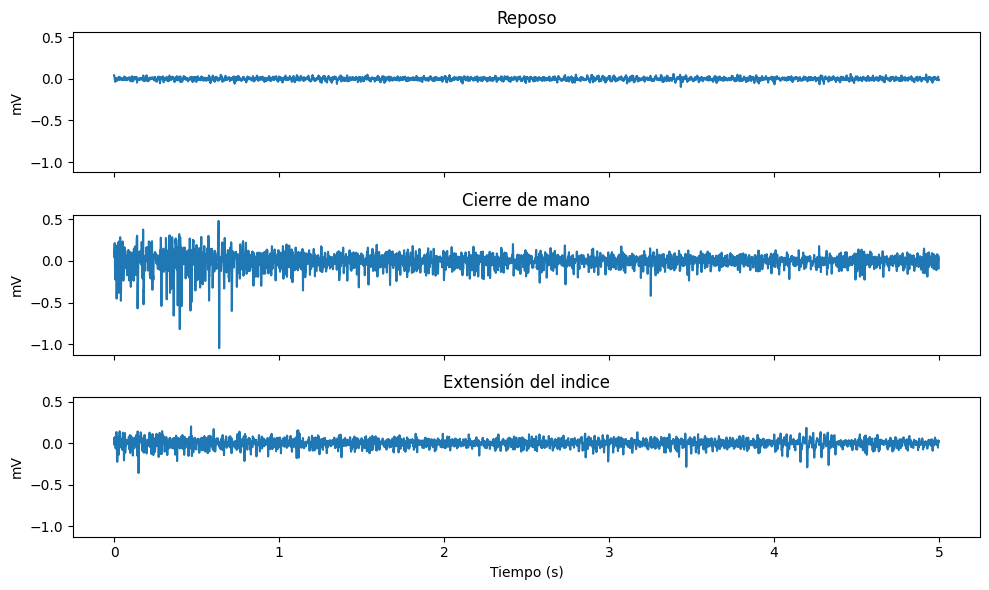

In [3]:
!pip install wfdb
import wfdb
import numpy as np
import matplotlib.pyplot as plt

carpeta = "grabmyo/1.1.0/Session1/session1_participant1"
gestos = {"Reposo": 17, "Cierre de mano": 16, "Extensión del indice": 9}
canal = 11 # canal F12 (índice 11 en Python)

senales = {}

for nombre_g, k in gestos.items():
    rec = wfdb.rdrecord(f"session1_participant1_gesture{k}_trial1", pn_dir=carpeta)
    senales[nombre_g] = rec.p_signal[:, canal]

fig, ax = plt.subplots(3, 1, sharex=True, sharey=True, figsize=(10, 6))

for a, (nombre_g, x) in zip(ax, senales.items()):
    a.plot(np.arange(len(x)) / rec.fs, x)
    a.set_title(nombre_g)
    a.set_ylabel("mV")

ax[-1].set_xlabel("Tiempo (s)")
plt.tight_layout()
plt.show()


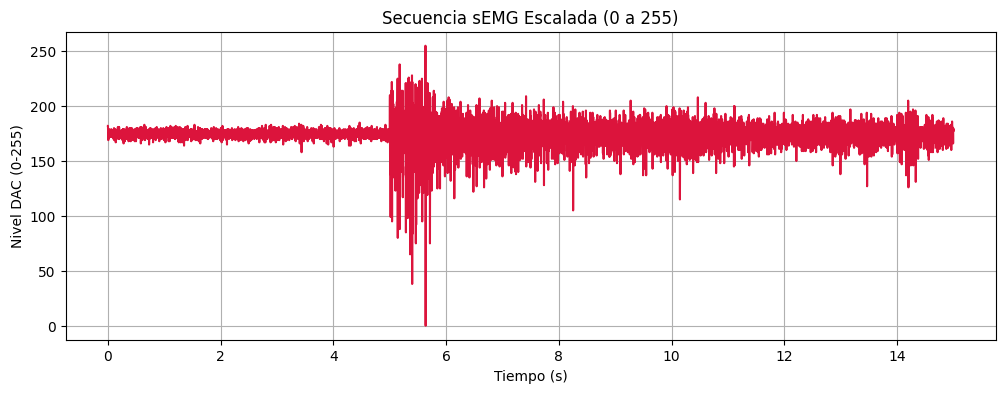

¡Archivo semg.h creado con éxito!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# 1. Concatenar las 3 señales en el orden: Reposo -> Cierre de mano -> Extensión del índice
secuencia_raw = np.concatenate([
    senales["Reposo"],
    senales["Cierre de mano"],
    senales["Extensión del indice"]
])

# 2. Escalar linealmente TODA la secuencia al rango [0, 255]
v_min = np.min(secuencia_raw)
v_max = np.max(secuencia_raw)

# Transformación lineal a flotante entre 0 y 255
secuencia_escalada = 255 * (secuencia_raw - v_min) / (v_max - v_min)

# Convertir a enteros sin signo de 8 bits (uint8)
secuencia_dac = np.round(secuencia_escalada).astype(np.uint8)

# 3. Graficar la secuencia combinada para verificar
plt.figure(figsize=(12, 4))
tiempo_total = np.arange(len(secuencia_dac)) / rec.fs
plt.plot(tiempo_total, secuencia_dac, color='crimson')
plt.title("Secuencia sEMG Escalada (0 a 255)")
plt.xlabel("Tiempo (s)")
plt.ylabel("Nivel DAC (0-255)")
plt.grid(True)
plt.show()

# 4. Generar y exportar el archivo semg.h
contenido_h = f"""#ifndef SEMG_H
#define SEMG_H

#include <Arduino.h>

const uint16_t N_SEMG = {len(secuencia_dac)};
const float FS_SEMG = {rec.fs};

const uint8_t SEMG[] PROGMEM = {{
    """

# Dar formato al arreglo en filas de 16 valores para legibilidad
lineas = []
for i in range(0, len(secuencia_dac), 16):
    bloque = ", ".join(map(str, secuencia_dac[i:i+16]))
    lineas.append(bloque)

contenido_h += ",\n    ".join(lineas)
contenido_h += "\n};\n\n#endif\n"

# Escribir el archivo semg.h
with open("semg.h", "w") as f:
    f.write(contenido_h)

print("¡Archivo semg.h creado con éxito!")

# Descargar semg.h a tu computadora automáticamente
from google.colab import files
files.download("semg.h")